# Descarte de "relevos" de qubit en la validacion de Dynamical Decoupling

## Pregunta a responder
La corrida anterior solo mide el qubit objetivo. Si el backend/transpilador
"relevara" (SWAP) la informacion hacia otro qubit fisico, o si hay crosstalk que
mueve poblacion a un vecino, observar solo el objetivo podria hacer ver como
"decoherencia" algo que en realidad es fuga/relevo hacia otro qubit — y el
sistema global seguiria siendo coherente, solo que en otro lugar.

## Que hace este notebook (1 solo job)
1. **Verificacion estructural**: revisa el circuito transpilado — cuenta swaps,
   confirma que el qubit objetivo sigue siendo el mismo fisico del principio al
   final (sin relevo logico va layout).
2. **Verificacion fisica (crosstalk/fuga)**: en el mismo circuito, ademas del
   qubit objetivo, se miden en paralelo 2 vecinos directos (acoplados en el mapa
   de conectividad) y 1 qubit de control lejano (distancia >= 3, sin acoplamiento
   directo). Los vecinos/control no reciben ninguna puerta — solo esperan el
   mismo tiempo `t` y se miden. Si el objetivo "cae" pero los vecinos NO suben
   por encima del error de lectura basal, la caida es decoherencia real del
   objetivo, no un relevo. Si los vecinos suben correlacionado con la caida del
   objetivo, hay fuga/crosstalk que si podria explicar (parte de) la caida.

## Diseno
Mismos protocolos y T_STEPS (escalados a T2 del qubit) que el notebook corregido
anterior. Un solo job, 4 qubits por circuito (objetivo + 2 vecinos + 1 control),
mismos SHOTS.


## 1. Instalacion


In [5]:
%pip install -q "qiskit>=1.0" "qiskit-ibm-runtime>=0.23" matplotlib scipy
print("OK")


Note: you may need to restart the kernel to use updated packages.
OK


## 2. Circuitos y utilidades


In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from qiskit import QuantumCircuit, transpile


def build_free(t_us, n_qubits):
    """Qubit 0 = objetivo (H-delay-H). Resto = vecinos/control, idle el mismo t."""
    qc = QuantumCircuit(n_qubits, n_qubits, name=f"free_{t_us}")
    qc.h(0)
    if t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
        for q in range(1, n_qubits):
            qc.delay(float(t_us), q, unit="us")
    qc.h(0)
    qc.barrier()
    qc.measure(range(n_qubits), range(n_qubits))
    return qc


def build_cpmg(t_us, n_qubits, n_pulses=6):
    qc = QuantumCircuit(n_qubits, n_qubits, name=f"cpmg_{t_us}_N{n_pulses}")
    qc.h(0)
    if n_pulses >= 1 and t_us > 0:
        seg = t_us / n_pulses
        for _ in range(n_pulses):
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            qc.x(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    for q in range(1, n_qubits):
        if t_us > 0:
            qc.delay(float(t_us), q, unit="us")
    qc.h(0)
    qc.barrier()
    qc.measure(range(n_qubits), range(n_qubits))
    return qc


def build_xy4(t_us, n_qubits, n_cycles=2):
    axes = (["x", "y", "x", "y"] * max(n_cycles, 1))
    n = len(axes)
    qc = QuantumCircuit(n_qubits, n_qubits, name=f"xy4_{t_us}_C{n_cycles}")
    qc.h(0)
    if n >= 1 and t_us > 0:
        seg = t_us / n
        for a in axes:
            h = seg / 2.0
            if h > 0:
                qc.delay(h, 0, unit="us")
            if a == "x":
                qc.x(0)
            else:
                qc.y(0)
            if h > 0:
                qc.delay(h, 0, unit="us")
    elif t_us > 0:
        qc.delay(float(t_us), 0, unit="us")
    for q in range(1, n_qubits):
        if t_us > 0:
            qc.delay(float(t_us), q, unit="us")
    qc.h(0)
    qc.barrier()
    qc.measure(range(n_qubits), range(n_qubits))
    return qc


def expect_x_bit(counts: dict, bit_index_from_right: int) -> float:
    """<X> del qubit correspondiente al bit en esa posicion (0=el mas a la derecha)."""
    n0 = n1 = 0
    for k, v in counts.items():
        bits = str(k).replace(" ", "")
        bit = bits[-1 - bit_index_from_right]
        if bit == "0":
            n0 += int(v)
        else:
            n1 += int(v)
    tot = n0 + n1
    return (n0 - n1) / tot if tot else 0.0


def p1_bit(counts: dict, bit_index_from_right: int) -> float:
    n0 = n1 = 0
    for k, v in counts.items():
        bits = str(k).replace(" ", "")
        bit = bits[-1 - bit_index_from_right]
        if bit == "0":
            n0 += int(v)
        else:
            n1 += int(v)
    tot = n0 + n1
    return n1 / tot if tot else 0.0


def counts_from_pub(pub) -> dict:
    data = pub.data
    if hasattr(data, "c"):
        return data.c.get_counts()
    for key in data:
        try:
            return data[key].get_counts()
        except Exception:
            continue
    return {}


def get_token() -> str:
    try:
        from kaggle_secrets import UserSecretsClient
        t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")
        if t:
            return t.strip()
    except Exception:
        pass
    t = os.environ.get("QISKIT_IBM_TOKEN") or os.environ.get("IBM_QUANTUM_TOKEN")
    if not t:
        raise RuntimeError("Configure secret IBM_QUANTUM_TOKEN")
    return t.strip()


def stretched_exp(t, A, T2, beta, C):
    return A * np.exp(-((np.maximum(t, 1e-12) / max(T2, 1e-12)) ** beta)) + C


def ramsey_damped_cos(t, A, f, phi, T2, C):
    return A * np.cos(2 * np.pi * f * t + phi) * np.exp(-(np.maximum(t, 1e-12) / max(T2, 1e-12))) + C


def fit_t2(times, signal):
    y = np.abs(np.asarray(signal, dtype=float))
    t = np.asarray(times, dtype=float)
    if len(t) < 3 or np.nanmax(y) < 0.05:
        return None
    A0 = float(np.clip(y[0] - y[-1], 0.05, 1.0))
    C0 = float(np.clip(y[-1], -0.2, 0.5))
    T0 = float(np.clip(t[len(t) // 2], 1.0, t[-1]))
    try:
        popt, pcov = curve_fit(
            stretched_exp, t, y, p0=[A0, T0, 1.2, C0],
            bounds=([0.0, 0.1, 0.3, -0.3], [1.5, t[-1] * 5, 3.0, 0.6]), maxfev=8000,
        )
        A, T2, beta, C = popt
        perr = np.sqrt(np.diag(pcov))
        return {"A": float(A), "T2": float(T2), "beta": float(beta), "C": float(C),
                "T2_err": float(perr[1]), "beta_err": float(perr[2]),
                "y_fit": stretched_exp(t, *popt), "reliable": bool(perr[1] < T2)}
    except Exception as e:
        print("Fit fallo:", e)
        return None


def fit_ramsey(times, signal):
    y = np.asarray(signal, dtype=float)
    t = np.asarray(times, dtype=float)
    if len(t) < 4:
        return None
    C0 = 0.0
    A0 = float(np.clip(np.max(np.abs(y - C0)), 0.05, 1.5))
    span = t[-1] - t[0] if t[-1] > t[0] else 1.0
    f0_candidates = [0.5 / span, 1.0 / span, 2.0 / span, 0.02, 0.05, 0.1]
    best = None
    for f0 in f0_candidates:
        try:
            popt, pcov = curve_fit(
                ramsey_damped_cos, t, y, p0=[A0, f0, 0.0, span * 2, C0],
                bounds=([0.0, 0.0, -np.pi, 0.1, -0.5], [1.5, 5.0, np.pi, span * 50, 0.5]),
                maxfev=20000,
            )
            resid = np.sum((ramsey_damped_cos(t, *popt) - y) ** 2)
            if best is None or resid < best[0]:
                perr = np.sqrt(np.diag(pcov))
                best = (resid, popt, perr)
        except Exception:
            continue
    if best is None:
        return None
    _, popt, perr = best
    A, f, phi, T2, C = popt
    return {"A": float(A), "f": float(f), "phi": float(phi), "T2": float(T2), "C": float(C),
            "f_err": float(perr[1]), "T2_err": float(perr[3]),
            "y_fit": ramsey_damped_cos(t, *popt),
            "reliable": bool(perr[3] < T2 and perr[1] < max(f, 1e-6))}


def bfs_distances(edges, n_qubits, source):
    adj = {q: set() for q in range(n_qubits)}
    for a, b in edges:
        adj[a].add(b); adj[b].add(a)
    dist = {source: 0}
    frontier = [source]
    while frontier:
        nxt = []
        for u in frontier:
            for v in adj[u]:
                if v not in dist:
                    dist[v] = dist[u] + 1
                    nxt.append(v)
        frontier = nxt
    return dist, adj


print("Utilidades listas (con verificacion de relevos/crosstalk).")


Utilidades listas (con verificacion de relevos/crosstalk).


## 3. Backend, qubit objetivo, vecinos y control (para descartar relevos)


In [7]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

N_CPMG = 6
N_XY4_CYCLES = 2
SHOTS = 2048
BACKEND_NAME = "ibm_fez"
PROTOCOLS = ("free", "cpmg", "xy4")
T2_FRACTIONS = [0.05, 0.15, 0.3, 0.5, 0.75, 1.0, 1.5]

token = get_token()
QiskitRuntimeService.save_account(
    channel="ibm_cloud", token=token, instance="open-instance",
    overwrite=True, set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_cloud", instance="open-instance")

ops = service.backends(operational=True, simulator=False)
names = [b.name for b in ops]
print("Backends:", names)
backend = service.backend(BACKEND_NAME) if BACKEND_NAME in names else ops[0]
print("Usando:", backend.name)


def pick_best_qubit(backend):
    props = backend.properties()
    best_q, best_score, best_t2_us = 0, -1.0, 100.0
    rows = []
    for q in range(backend.num_qubits):
        try:
            t2 = props.t2(q)
        except Exception:
            continue
        if t2 is None:
            continue
        err = None
        for g in ("sx", "x"):
            try:
                err = props.gate_error(g, [q])
                break
            except Exception:
                pass
        t2_us = t2 * 1e6
        gate_pen = err if err is not None else 0.01
        score = t2_us / (1.0 + 50.0 * gate_pen)
        rows.append((q, t2_us, err, score))
        if score > best_score:
            best_score, best_q, best_t2_us = score, q, t2_us
    rows.sort(key=lambda r: -r[3])
    print("Top 5 qubits (T2 / error):")
    for q, t2u, err, sc in rows[:5]:
        print(f"  q={q:3d}  T2={t2u:7.1f} us  err={err}  score={sc:.2f}")
    if not rows:
        return 0, 100.0
    print("Seleccionado qubit fisico objetivo:", best_q, " T2=%.1fus" % best_t2_us)
    return best_q, best_t2_us


target_q, target_t2_us = pick_best_qubit(backend)

edges = [tuple(e) for e in backend.coupling_map.get_edges()]
dist, adj = bfs_distances(edges, backend.num_qubits, target_q)

# Vecinos directos (distancia 1), hasta 2, priorizando mejor T2 disponible
props = backend.properties()
def t2_of(q):
    try:
        t2 = props.t2(q)
        return t2 * 1e6 if t2 else 0.0
    except Exception:
        return 0.0

neighbor_candidates = sorted([q for q, d in dist.items() if d == 1], key=lambda q: -t2_of(q))
neighbors = neighbor_candidates[:2]
if not neighbors:
    raise RuntimeError("El qubit elegido no tiene vecinos en el mapa de acoplamiento; elige otro backend.")

# Control lejano: distancia >= 3 del objetivo (sin acoplamiento directo ni via 1 salto), mejor T2
far_candidates = sorted([q for q, d in dist.items() if d >= 3], key=lambda q: -t2_of(q))
if not far_candidates:
    far_candidates = sorted([q for q, d in dist.items() if d >= 2], key=lambda q: -t2_of(q))
control_q = far_candidates[0] if far_candidates else None
if control_q is None:
    raise RuntimeError("No se encontro qubit de control suficientemente lejano en este backend.")

physical_qubits = [target_q] + neighbors + [control_q]
n_qubits = len(physical_qubits)
print(f"\nObjetivo (bit0): q{target_q}  T2={target_t2_us:.1f}us")
print(f"Vecinos directos (bit1,bit2): {neighbors}  (distancia=1 del objetivo)")
print(f"Control lejano (bit3): q{control_q}  (distancia={dist[control_q]} del objetivo, sin acoplamiento directo)")
print(f"Total qubits fisicos en el circuito: {n_qubits}  -> {physical_qubits}")

T_STEPS = sorted(set(round(f * target_t2_us, 1) for f in T2_FRACTIONS))
print("T_STEPS (us), escalados a T2 del objetivo:", T_STEPS)


Backends: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Usando: ibm_fez
Top 5 qubits (T2 / error):
  q=142  T2=  265.1 us  err=0.0003976411056252661  score=259.89
  q= 15  T2=  257.4 us  err=0.0002456479545288483  score=254.31
  q= 88  T2=  252.8 us  err=0.0003841744382059813  score=248.03
  q=127  T2=  213.0 us  err=0.00027888631720206653  score=210.04
  q=  1  T2=  211.6 us  err=0.000340812727879291  score=208.04
Seleccionado qubit fisico objetivo: 142  T2=265.1us

Objetivo (bit0): q142  T2=265.1us
Vecinos directos (bit1,bit2): [143, 141]  (distancia=1 del objetivo)
Control lejano (bit3): q15  (distancia=27 del objetivo, sin acoplamiento directo)
Total qubits fisicos en el circuito: 4  -> [142, 143, 141, 15]
T_STEPS (us), escalados a T2 del objetivo: [13.3, 39.8, 79.5, 132.5, 198.8, 265.1, 397.6]


## 4. Circuito unico: objetivo + vecinos + control, mismo t, sin puertas en vecinos/control


In [8]:
circuits = []
index = []
for t in T_STEPS:
    circuits.append(build_free(t, n_qubits)); index.append(("free", t))
    circuits.append(build_cpmg(t, n_qubits, N_CPMG)); index.append(("cpmg", t))
    circuits.append(build_xy4(t, n_qubits, N_XY4_CYCLES)); index.append(("xy4", t))

print(f"Circuitos en el lote: {len(circuits)}  (1 job, {SHOTS} shots, {n_qubits} qubits/circuito)")

# initial_layout fija el mapeo logico->fisico: bit0->target_q, bit1,bit2->vecinos, bit3->control_q
transpiled = transpile(
    circuits, backend=backend, optimization_level=1, initial_layout=physical_qubits,
)

# --- Verificacion ESTRUCTURAL de relevos (swaps) ---
print("\n--- Verificacion estructural (sin ejecutar hardware) ---")
any_swap = False
for i, tc in enumerate(transpiled):
    ops_count = tc.count_ops()
    n_swaps = ops_count.get("swap", 0)
    if n_swaps > 0:
        any_swap = True
        print(f"  circuito {i} ({index[i]}): {n_swaps} SWAP(s) detectados -> el objetivo pudo relevarse")
    try:
        final_layout = tc.layout.final_index_layout() if tc.layout is not None else None
    except Exception:
        final_layout = None
    if final_layout is not None and len(final_layout) > 0:
        # final_layout[i] = qubit fisico que termina ocupando la posicion logica i
        if final_layout[0] != physical_qubits[0]:
            any_swap = True
            print(f"  circuito {i} ({index[i]}): layout final del objetivo cambio de q{physical_qubits[0]} a q{final_layout[0]}")

if not any_swap:
    print("OK: ningun circuito tiene SWAPs y el objetivo permanece en el mismo qubit fisico "
          "del principio al final. No hay relevo logico posible en este disenio.")
else:
    print("ATENCION: se detecto reasignacion fisica del objetivo — la caida observada podria "
          "incluir movimiento de estado, no solo decoherencia. Revisar optimization_level o "
          "fijar mas restrictivamente el layout.")

sampler = SamplerV2(mode=backend)
job = sampler.run(transpiled, shots=SHOTS)
print("\nJob ID:", job.job_id())
print("Esperando (unica espera de cola)...")
result = job.result()
print("Job completado.")

JOB_ID = job.job_id()
BACKEND_USED = backend.name
TARGET_Q = target_q
NEIGHBORS = neighbors
CONTROL_Q = control_q
TARGET_T2_US = target_t2_us
INDEX = index
RESULT = result
T_STEPS_ARR = np.array(T_STEPS, dtype=float)


Circuitos en el lote: 21  (1 job, 2048 shots, 4 qubits/circuito)


/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 277 [dt] = 1.108000e-06 [s] from 1.108333e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 208 [dt] = 8.320000e-07 [s] from 8.312500e-07 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 829 [dt] = 3.316000e-06 [s] from 3.316667e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 622 [dt] = 2.488000e-06 [s] from 2.487500e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 1656 [dt] = 6.624000e-06 [s] from 6.625000e-06 [s]
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/qiskit/circuit/duration.py:37: UserWarning: Duration is rounded to 1242 [dt] = 4.968000e-


--- Verificacion estructural (sin ejecutar hardware) ---
OK: ningun circuito tiene SWAPs y el objetivo permanece en el mismo qubit fisico del principio al final. No hay relevo logico posible en este disenio.

Job ID: dapj8mac505c73ciad30
Esperando (unica espera de cola)...
Job completado.


## 5. Analisis: decae el objetivo Y aparece algo en vecinos/control (fuga/relevo), o solo el objetivo cambia


Backend=ibm_fez  objetivo=q142  vecinos=[143, 141]  control=q15  job=dapj8mac505c73ciad30

  t (us)   proto    <X> obj   P1 vecinos   P1 control
-------------------------------------------------------
    13.3    free    -0.6211       0.0005       0.0137
    39.8    free    +0.5811       0.0010       0.0215
    79.5    free    +0.0459       0.0012       0.0239
   132.5    free    -0.0986       0.0022       0.0229
   198.8    free    -0.2012       0.0022       0.0229
   265.1    free    -0.1514       0.0017       0.0176
   397.6    free    -0.0244       0.0007       0.0151
    13.3    cpmg    +0.8398       0.0015       0.0205
    39.8    cpmg    +0.7852       0.0015       0.0156
    79.5    cpmg    +0.6270       0.0017       0.0176
   132.5    cpmg    +0.4463       0.0007       0.0161
   198.8    cpmg    +0.3027       0.0022       0.0122
   265.1    cpmg    +0.2363       0.0010       0.0176
   397.6    cpmg    +0.1436       0.0005       0.0146
    13.3     xy4    +0.8447       0.0015   

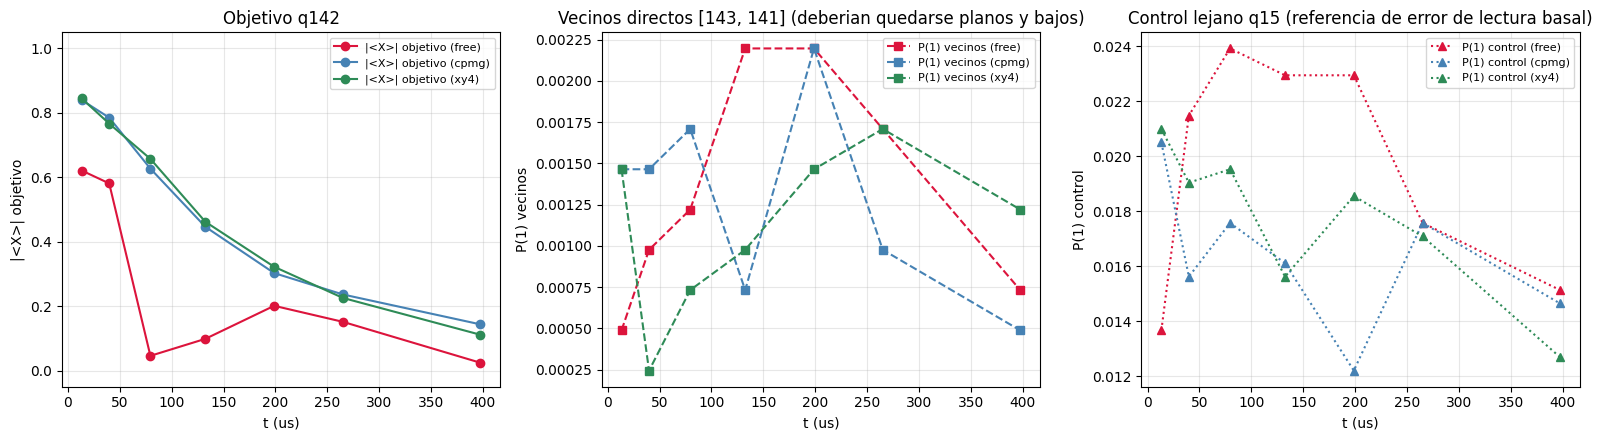


Piso de error de lectura (control lejano, promedio de protocolos): 0.0179
P(1) promedio en vecinos: 0.0013
VEREDICTO: los vecinos se quedan al nivel del piso de lectura basal, sin subir cuando el objetivo 'cae'. NO hay evidencia de relevo/fuga hacia vecinos: la caida observada en el objetivo es decoherencia/detuning real de ese qubit, no un espejismo.


In [9]:
series_x = {p: [] for p in PROTOCOLS}       # <X> del objetivo (bit 0)
series_neighbor_p1 = {p: [] for p in PROTOCOLS}  # P(1) promedio de los 2 vecinos (bit 1,2)
series_control_p1 = {p: [] for p in PROTOCOLS}   # P(1) del control lejano (bit 3)

for i, (prot, t) in enumerate(INDEX):
    counts = counts_from_pub(RESULT[i])
    series_x[prot].append(expect_x_bit(counts, 0))
    p1_nb = np.mean([p1_bit(counts, b) for b in (1, 2)])
    series_neighbor_p1[prot].append(p1_nb)
    series_control_p1[prot].append(p1_bit(counts, 3))

for p in PROTOCOLS:
    series_x[p] = np.array(series_x[p], dtype=float)
    series_neighbor_p1[p] = np.array(series_neighbor_p1[p], dtype=float)
    series_control_p1[p] = np.array(series_control_p1[p], dtype=float)

print(f"Backend={BACKEND_USED}  objetivo=q{TARGET_Q}  vecinos={NEIGHBORS}  control=q{CONTROL_Q}  job={JOB_ID}\n")
print(f"{'t (us)':>8}  {'proto':>6}  {'<X> obj':>9}  {'P1 vecinos':>11}  {'P1 control':>11}")
print("-" * 55)
for p in PROTOCOLS:
    for i, t in enumerate(T_STEPS_ARR):
        print(f"{t:8.1f}  {p:>6}  {series_x[p][i]:+9.4f}  {series_neighbor_p1[p][i]:11.4f}  {series_control_p1[p][i]:11.4f}")

# Correlacion entre "caida" del objetivo y "subida" en vecinos/control (por protocolo)
print("\nCorrelacion entre |<X>_objetivo caida| y P(1) vecinos/control (por protocolo):")
for p in PROTOCOLS:
    decay_signal = 1.0 - np.abs(series_x[p])  # 0 si sigue coherente, ->1 si "cayo"
    if np.std(decay_signal) > 1e-9 and np.std(series_neighbor_p1[p]) > 1e-9:
        r_nb = np.corrcoef(decay_signal, series_neighbor_p1[p])[0, 1]
    else:
        r_nb = float("nan")
    if np.std(decay_signal) > 1e-9 and np.std(series_control_p1[p]) > 1e-9:
        r_ct = np.corrcoef(decay_signal, series_control_p1[p])[0, 1]
    else:
        r_ct = float("nan")
    print(f"  {p:>6}: corr(caida_objetivo, P1_vecinos)={r_nb:+.2f}   corr(caida_objetivo, P1_control)={r_ct:+.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = {"free": "crimson", "cpmg": "steelblue", "xy4": "seagreen"}

ax = axes[0]
for p in PROTOCOLS:
    ax.plot(T_STEPS_ARR, np.abs(series_x[p]), "o-", color=colors[p], label=f"|<X>| objetivo ({p})")
ax.set_xlabel("t (us)"); ax.set_ylabel("|<X>| objetivo")
ax.set_title(f"Objetivo q{TARGET_Q}")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3); ax.set_ylim(-0.05, 1.05)

ax = axes[1]
baseline = None
for p in PROTOCOLS:
    ax.plot(T_STEPS_ARR, series_neighbor_p1[p], "s--", color=colors[p], label=f"P(1) vecinos ({p})")
ax.set_xlabel("t (us)"); ax.set_ylabel("P(1) vecinos")
ax.set_title(f"Vecinos directos {NEIGHBORS} (deberian quedarse planos y bajos)")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]
for p in PROTOCOLS:
    ax.plot(T_STEPS_ARR, series_control_p1[p], "^:", color=colors[p], label=f"P(1) control ({p})")
ax.set_xlabel("t (us)"); ax.set_ylabel("P(1) control")
ax.set_title(f"Control lejano q{CONTROL_Q} (referencia de error de lectura basal)")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

print("\n" + "=" * 70)
readout_floor = float(np.mean([series_control_p1[p].mean() for p in PROTOCOLS]))
print(f"Piso de error de lectura (control lejano, promedio de protocolos): {readout_floor:.4f}")
neighbor_avg = float(np.mean([series_neighbor_p1[p].mean() for p in PROTOCOLS]))
print(f"P(1) promedio en vecinos: {neighbor_avg:.4f}")

if neighbor_avg <= readout_floor * 1.5:
    print("VEREDICTO: los vecinos se quedan al nivel del piso de lectura basal, sin subir "
          "cuando el objetivo 'cae'. NO hay evidencia de relevo/fuga hacia vecinos: la caida "
          "observada en el objetivo es decoherencia/detuning real de ese qubit, no un espejismo.")
else:
    print("VEREDICTO: los vecinos muestran poblacion por encima del piso de lectura basal, y "
          "posiblemente correlacionada con la caida del objetivo (ver correlaciones arriba). "
          "Esto es compatible con fuga/crosstalk: parte de lo que parece decoherencia podria "
          "ser relevo real de estado hacia el vecino, no perdida de informacion del sistema.")
print("=" * 70)


## 6. Interpretacion

### Que descarta / confirma este notebook
- **Relevo logico (SWAP/relayout)**: la celda 4 revisa el circuito transpilado — si no
  hay SWAPs y el layout final del objetivo es el mismo fisico del inicio, se descarta
  por diseno (no hay como el algoritmo "relevara" el qubit sin que aparezca un SWAP).
- **Fuga fisica / crosstalk hacia vecinos**: si `P(1)` en los vecinos se mantiene al
  nivel del piso de lectura del control lejano (que no tiene ninguna puerta ni
  acoplamiento), la caida del objetivo es decoherencia real y localizada — no hay
  "sistema global que sigue siendo estable" mientras el objetivo aparenta caer.
- Si en cambio los vecinos suben y correlacionan con la caida del objetivo, es
  evidencia de fuga real y justificaria revisar si el T2 medido antes esta
  subestimado (parte de la "perdida" en realidad se movio, no desaparecio).

### Limite de este disenio
Esto descarta relevo hacia los **vecinos directos** y confirma ausencia de **SWAP
logico** en el circuito. No cubre fugas hacia qubits no vecinos via crosstalk de
largo alcance (mas raro, pero posible en el chip) — si el veredicto sale positivo
y quieres blindarlo mas, se puede repetir midiendo un anillo mas amplio de vecinos
a costo de mas qubits en el mismo job (mismo numero de circuitos, mismo tiempo).
